DOKUMENTASI PROGRAM & ANALISIS DATASET

1. JENIS TUGAS PEMODELAN: MULTICLASS CLASSIFICATION
   Program ini tergolong ke dalam tugas KLASIFIKASI MULTI-KELAS (MULTICLASS CLASSIFICATION).
   Alasan utamanya adalah variabel target yang diprediksi ('quality') memiliki LEBIH DARI 2 
   KELAS KATEGORI DISKRIT, yaitu terdiri dari 6 nilai kualitas unik (3, 4, 5, 6, 7, 8). 
   Tugas ini bukan klasifikasi biner (yang hanya 2 kelas) dan bukan multilabel (karena 
   setiap baris data hanya memiliki tepat 1 label kualitas).

2. JUMLAH DATASET:
   Dataset mentah terdiri dari 1.599 baris/sampel data dan 12 kolom (11 fitur + 1 target).
   Catatan: Setelah dilakukan proses pembersihan data duplikat (Data Cleaning), jumlah data 
   yang diproses menjadi 1.359 baris data unik.

3. LABEL / VARIABEL YANG DIGUNAKAN:
   - Variabel Target (y / Label Output): 
     Kolom 'quality' (bernilai 3, 4, 5, 6, 7, atau 8).
   - Variabel Fitur (X / Label Input - 11 Fitur Fisikokimia):
     1. fixed acidity        5. chlorides              9. pH
     2. volatile acidity     6. free sulfur dioxide   10. sulphates
     3. citric acid          7. total sulfur dioxide  11. alcohol
     4. residual sugar       8. density

4. RINGKASAN ALUR KERJA SESUAI TAHAPAN DOSEN:
   - Data Collecting       : Memuat dataset 'red-wine.csv'.
   - Data Cleaning         : Mengidentifikasi 0 missing values dan menghapus data duplikat.
   - EDA & EXDA            : Visualisasi distribusi kelas target dan korelasi antar fitur.
   - Data Processing       : Standarisasi nilai fitur menggunakan StandardScaler.
   - Data Splitting        : Membagi data (80% Train, 20% Test) dengan Stratified Sampling.
   - Modelling & Evaluasi  : Membangun model RandomForestClassifier(class_weight='balanced') 
                             dan mengevaluasi performa dengan Confusion Matrix & F1-Score.
   - Deployment            : Menyimpan artefak model ('red_wine_multiclass_model.pkl') 
                             dan scaler ('scaler.pkl') menggunakan joblib.

In [6]:
import pandas as pd

# Load dataset
df = pd.read_csv('redwine.csv')
print(f"Ukuran Dataset: {df.shape[0]} baris, {df.shape[1]} kolom")

Ukuran Dataset: 1599 baris, 12 kolom


In [7]:
# Cek missing values
print("Missing values per kolom:\n", df.isnull().sum())

# Cek dan hapus data duplikat (jika ada)
duplicates = df.duplicated().sum()
print(f"Jumlah baris duplikat: {duplicates}")
if duplicates > 0:
    df = df.drop_duplicates().reset_index(drop=True)

Missing values per kolom:
 fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64
Jumlah baris duplikat: 240


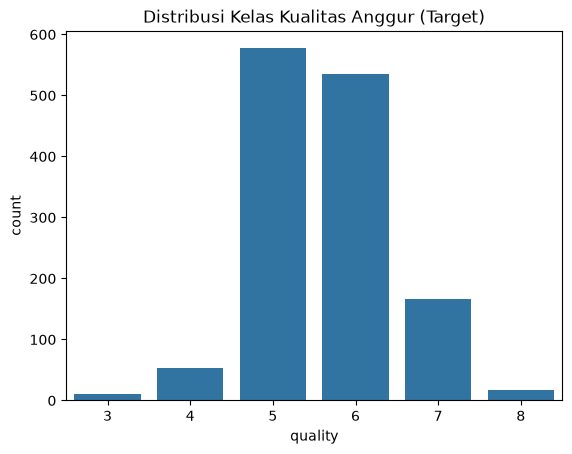

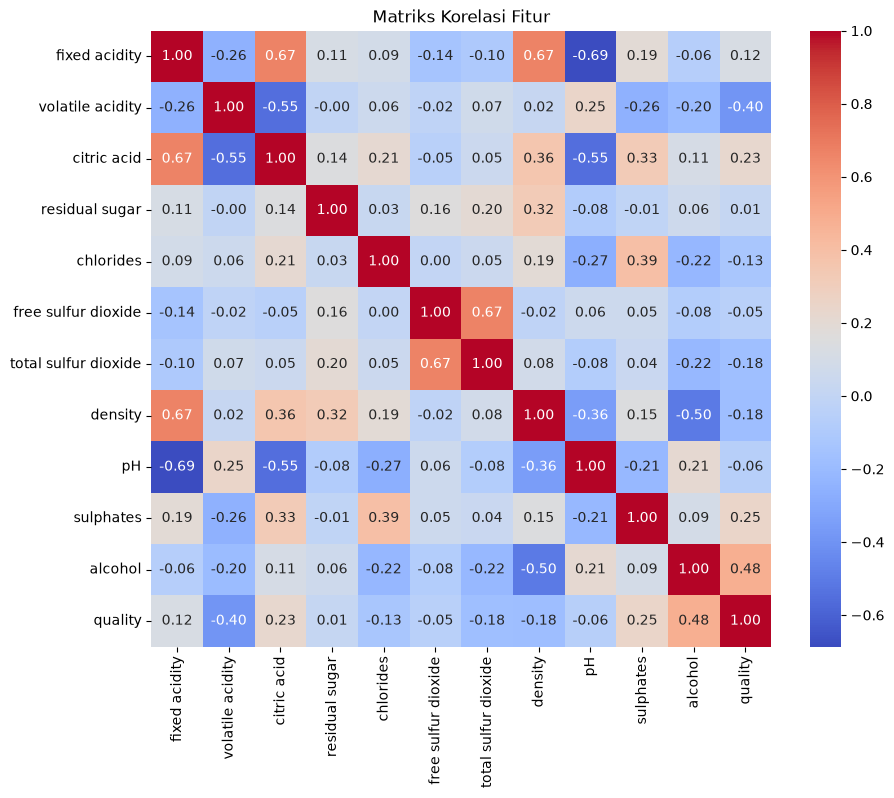

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Distribusi Target
sns.countplot(x='quality', data=df)
plt.title('Distribusi Kelas Kualitas Anggur (Target)')
plt.show()

# Heatmap Korelasi Fitur dengan Target
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Matriks Korelasi Fitur')
plt.show()

In [9]:
from sklearn.preprocessing import StandardScaler

# Pemisahan X dan y
X = df.drop(columns=['quality'])
y = df['quality']

# Pengskalaan Fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Inisialisasi & Latih Model dengan class_weight='balanced'
model = RandomForestClassifier(class_weight='balanced', random_state=42)
model.fit(X_train, y_train)

# Prediksi Data Uji
y_pred = model.predict(X_test)

# Evaluasi (Tambahkan zero_division=0)
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred, zero_division=0))

Confusion Matrix:
 [[ 0  0  1  1  0  0]
 [ 0  0  6  5  0  0]
 [ 0  1 81 34  0  0]
 [ 0  0 28 69 10  0]
 [ 0  0  3 19 10  1]
 [ 0  0  0  2  1  0]]

Classification Report:
               precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00        11
           5       0.68      0.70      0.69       116
           6       0.53      0.64      0.58       107
           7       0.48      0.30      0.37        33
           8       0.00      0.00      0.00         3

    accuracy                           0.59       272
   macro avg       0.28      0.27      0.27       272
weighted avg       0.56      0.59      0.57       272



In [12]:
import joblib

# Menyimpan Model dan Scaler untuk Deployment
joblib.dump(model, 'red_wine_multiclass_model.pkl')
joblib.dump(scaler, 'scaler.pkl')

print("Model dan Scaler berhasil disimpan untuk tahap Deployment.")

Model dan Scaler berhasil disimpan untuk tahap Deployment.
